In [ ]:
try:
    import dolfinx
except ImportError:
    !wget "https://fem-on-colab.github.io/releases/fenicsx-install-release-complex.sh" -O "/tmp/fenicsx-install.sh" && bash "/tmp/fenicsx-install.sh"
    import dolfinx

In [ ]:
try:
    import meshio
except ImportError:
    !pip install meshio
    import meshio

In [ ]:
import meshio
from mpi4py import MPI
import numpy as np

proc = MPI.COMM_WORLD.rank
def create_mesh(mesh, cell_type, prune_z=False):
    cells = mesh.get_cells_type(cell_type)
    cell_data = mesh.get_cell_data("gmsh:physical", cell_type)
    points = mesh.points[:, :2] if prune_z else mesh.points
    out_mesh = meshio.Mesh(points=points, cells={cell_type: cells},
    cell_data={"name_to_read": [cell_data.astype(np.int32)]})
    return out_mesh
if proc == 0:
    msh = meshio.read("mesh.msh")
    tetra_mesh = create_mesh(msh, "triangle", prune_z=True)
    triangle_mesh = create_mesh(msh, "line", prune_z=True)
    meshio.write("mesh.xdmf", tetra_mesh)
    meshio.write("mt.xdmf", triangle_mesh)
MPI.COMM_WORLD.barrier()

In [ ]:
from mpi4py import MPI
from dolfinx import mesh, fem, io
from dolfinx.io import XDMFFile
from dolfinx.fem import (Constant, dirichletbc, Function, functionspace, assemble_scalar, form, locate_dofs_geometrical, locate_dofs_topological)
from dolfinx.fem.petsc import LinearProblem
from ufl import Measure, TestFunction, TrialFunction, inner, grad, div, ds
import numpy as np
import ufl
from petsc4py import PETSc

# Определяем степень элемента в начале
degree = 2

with XDMFFile(MPI.COMM_WORLD, "mesh.xdmf", "r") as xdmf:
    mesh = xdmf.read_mesh(name="Grid")
    ct = xdmf.read_meshtags(mesh, name="Grid")
mesh.topology.create_connectivity(mesh.topology.dim, mesh.topology.dim-1)
with XDMFFile(MPI.COMM_WORLD, "mt.xdmf", "r") as xdmf:
    ft = xdmf.read_meshtags(mesh, name="Grid")

dx = Measure('dx', domain=mesh, subdomain_data=ct)
ds = Measure('ds', domain=mesh, subdomain_data=ft)

# Комплексные функциональные пространства
V = functionspace(mesh, ("CG", degree))
W0 = fem.functionspace(mesh, ("DG", 0))

# Волновое число (комплексное)
k0 = 1.0
k = fem.Constant(mesh, PETSc.ScalarType(k0 + 0j))

A = Function(W0)
A.x.array[:] = 1.0 + 0j
A.x.array[ct.find(2)] = 0.2 + 0j

n_coef = Function(W0)
n_coef.x.array[:] = 1.0 + 0j
n_coef.x.array[ct.find(2)] = 10.0 + 0j

# Падающая волна 𝑢_𝑖
x = ufl.SpatialCoordinate(mesh)
d = ufl.as_vector((1.0, 0.0))   # направление
u_i = ufl.exp(1j * k * ufl.dot(x, d))

# Правая часть 𝑓
I = ufl.Identity(mesh.geometry.dim)
f = (
    div((1.0 - A) * grad(u_i))
    + k**2 * (1.0 - n_coef) * u_i
)

u = TrialFunction(V)
v = TestFunction(V)

a = (
    inner(A * grad(u), grad(v)) * dx
    - k**2 * inner(n_coef * u, v) * dx
    - 1j * k * inner(u, v) * ds
)

L = - inner(f, v) * dx

gmres_problem = fem.petsc.LinearProblem(a, L, bcs=[], petsc_options={"ksp_type": "gmres","ksp_rtol": 1e-6, "ksp_atol": 1e-10, "ksp_max_it": 1000, "pc_type": "none"}, petsc_options_prefix="none")
uh = gmres_problem.solve()



In [ ]:
# @title Обработка данных
import pyvista
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Convert the DOLFINx mesh to a PyVista unstructured grid
pyvista.start_xvfb()
mesh.topology.create_connectivity(mesh.topology.dim, mesh.topology.dim)
p_mesh = pyvista.UnstructuredGrid(*dolfinx.plot.vtk_mesh(mesh, mesh.topology.dim))
pyvista_cells, cell_types, geometry = dolfinx.plot.vtk_mesh(V)
grid = pyvista.UnstructuredGrid(pyvista_cells, cell_types, geometry)

grid.point_data["u_s_real"] = uh.x.array.real
grid.point_data["u_s_imag"] = uh.x.array.imag

coords = grid.points
u_i_vals = np.exp(1j * k0 * coords[:, 0])

u_total = uh.x.array + u_i_vals

grid.point_data["u_i_real"] = u_i_vals.real
grid.point_data["u_i_imag"] = u_i_vals.imag

grid.point_data["u_real"] = u_i_vals.real + uh.x.array.real
grid.point_data["u_imag"] = u_i_vals.imag + uh.x.array.imag
grid.point_data["u_abs"]  = np.abs(u_total)

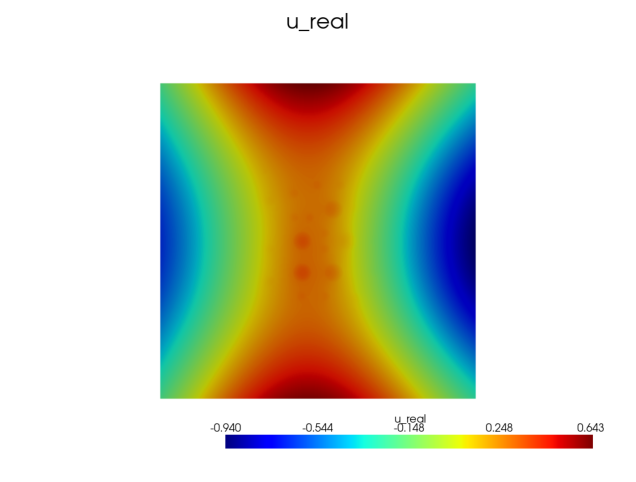

In [ ]:
# @title Решение $\text{Re}(u)$
grid.set_active_scalars("u_real")
p_abs = pyvista.Plotter(off_screen=True)
p_abs.add_text("u_real", position="upper_edge", font_size=14, color="black")
p_abs.add_mesh(grid, cmap="jet", show_edges=False)
p_abs.view_xy()
figure = p_abs.screenshot("u_real.png")

# вывод
img = mpimg.imread("u_real.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

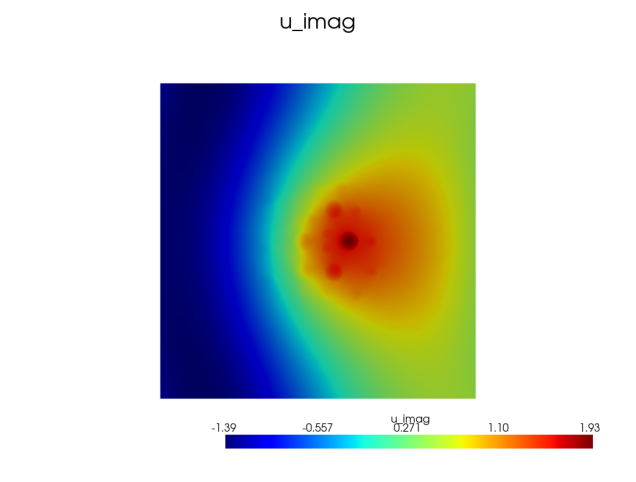

In [ ]:
# @title Решение $\text{Im}(u)$
grid.set_active_scalars("u_imag")
p_abs = pyvista.Plotter(off_screen=True)
p_abs.add_text("u_imag", position="upper_edge", font_size=14, color="black")
p_abs.add_mesh(grid, cmap="jet", show_edges=False)
p_abs.view_xy()
figure = p_abs.screenshot("u_imag.png")

# вывод
img = mpimg.imread("u_imag.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

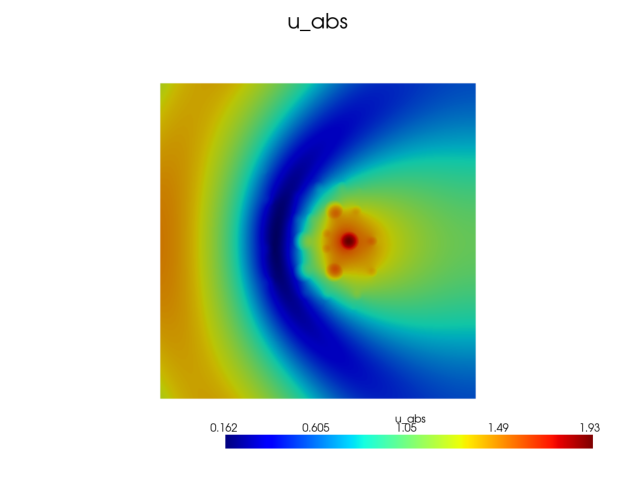

In [ ]:
# @title Решение $\text{Abs}(u)$
grid.set_active_scalars("u_abs")
p_abs = pyvista.Plotter(off_screen=True)
p_abs.add_text("u_abs", position="upper_edge", font_size=14, color="black")
p_abs.add_mesh(grid, cmap="jet", show_edges=False)
p_abs.view_xy()
figure = p_abs.screenshot("u_abs.png")

# вывод
img = mpimg.imread("u_abs.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

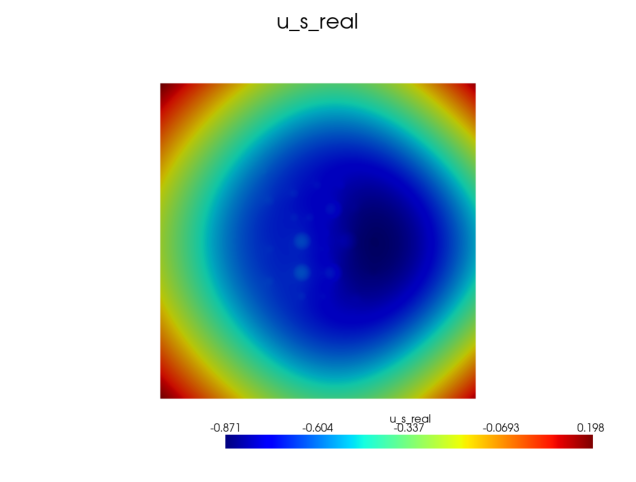

In [ ]:
# @title Решение $\text{Re}(u_s)$
_ = grid.set_active_scalars("u_s_real")

p_real = pyvista.Plotter(off_screen=True)
p_real.add_text("u_s_real", position="upper_edge", font_size=14, color="black")
p_real.add_mesh(grid, cmap="jet", show_edges=False)
p_real.view_xy()
figure = p_real.screenshot("u_s_real.png")

# вывод
img = mpimg.imread("u_s_real.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

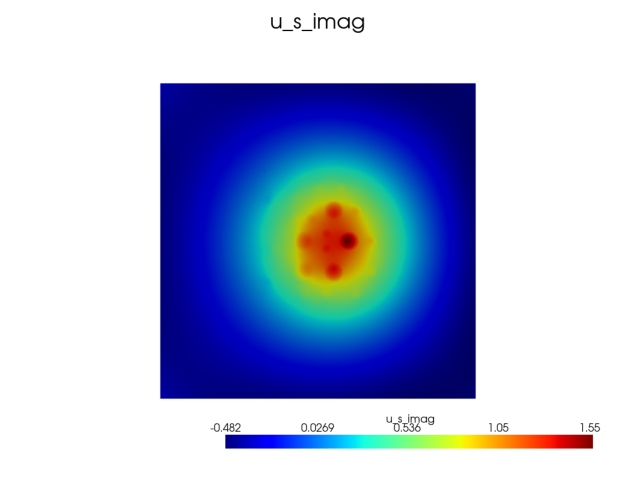

In [ ]:
# @title Решение $\text{Im}(u_s)$
_ = grid.set_active_scalars("u_s_imag")
p_imag = pyvista.Plotter(off_screen=True)
p_imag.add_text("u_s_imag", position="upper_edge", font_size=14, color="black")
p_imag.add_mesh(grid, cmap="jet", show_edges=False)
p_imag.view_xy()
figure = p_imag.screenshot("u_s_imag.png")

# вывод
img = mpimg.imread("u_s_imag.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")   # убрать оси
plt.show()

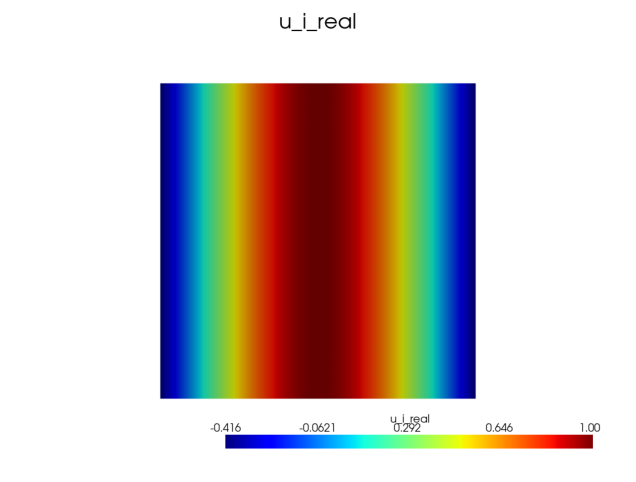

In [ ]:
# @title Решение $\text{Re}(u_i)$
grid.set_active_scalars("u_i_real")
p_real = pyvista.Plotter(off_screen=True)
p_real.add_text("u_i_real", position="upper_edge", font_size=14, color="black")
p_real.add_mesh(grid, cmap="jet", show_edges=False)
p_real.view_xy()
figure = p_real.screenshot("u_i_real.png")

# вывод
img = mpimg.imread("u_i_real.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

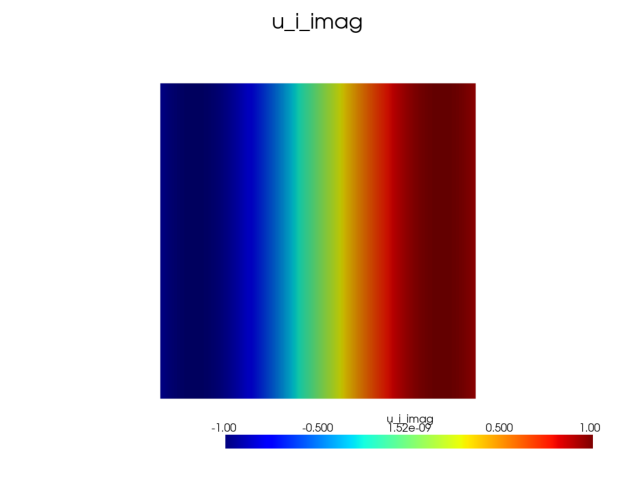

In [ ]:
# @title Решение $\text{Im}(u_i)$
grid.set_active_scalars("u_i_imag")
p_imag = pyvista.Plotter(off_screen=True)
p_imag.add_text("u_i_imag", position="upper_edge", font_size=14, color="black")
p_imag.add_mesh(grid, cmap="jet", show_edges=False)
p_imag.view_xy()
figure = p_imag.screenshot("u_i_imag.png")

# вывод
img = mpimg.imread("u_i_imag.png")
plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()



```geo
LX1 = -2.0;
LY1 = -2.0;
LX2 = 2.0;
LY2 = 2.0;
ls = 0.05;
ls2 = ls/2;
Point(1) = {LX1, LY1, 0, ls};
Point(2) = {LX1, LY2, 0, ls};
Point(3) = {LX2, LY2, 0, ls};
Point(4) = {LX2, LY1, 0, ls};

Line(1) = {1,2};
Line(2) = {2,3};
Line(3) = {3,4};
Line(4) = {4,1};

Line Loop(1) = {1,2,3,4};
loops[] = {};
Function circle
    CX = CX / 1000 * 4 - 2;
    CY = CY / 1000 * 4 - 2;
    s = S / 1000 * 2;
    s = s;
    p = newp; Point(p)   = {CX,CY,0,  ls2};
    p1 = newp; Point(p1) = {CX-s,CY,0,ls2};
    p2 = newp; Point(p2) = {CX,CY+s,0,ls2};
    p3 = newp; Point(p3) = {CX+s,CY,0,ls2};
    p4 = newp; Point(p4) = {CX,CY-s,0,ls2};
    
    l1 = newl; Circle(l1) = {p1,p,p2};
    l2 = newl; Circle(l2) = {p2,p,p3};
    l3 = newl; Circle(l3) = {p3,p,p4};
    l4 = newl; Circle(l4) = {p4,p,p1};

    sp = news; Line Loop(sp) = {l1,l2,l3,l4};
    Plane Surface(sp) = {sp};
    loops[] += {sp};

Return

CX = 615; CY = 285; S=10;
Call circle;

CX = 450; CY = 325; S=25;
Call circle;

CX = 525; CY = 325; S=25;
Call circle;

CX = 625; CY = 325; S=25;
Call circle;

CX = 350; CY = 375; S=25;
Call circle;

CX = 450; CY = 400; S=50;
Call circle;

CX = 550; CY = 400; S=50;
Call circle;

CX = 675; CY = 400; S=25;
Call circle;

CX = 350; CY = 475; S=25;
Call circle;

CX = 525; CY = 475; S=25;
Call circle;

CX = 450; CY = 500; S=50;
Call circle;

CX = 600; CY = 500; S=50;
Call circle;

CX = 675; CY = 500; S=25;
Call circle;

CX = 525; CY = 525; S=25;
Call circle;

CX = 425; CY = 575; S=25;
Call circle;

CX = 475; CY = 575; S=25;
Call circle;

CX = 550; CY = 600; S=50;
Call circle;

CX = 625; CY = 600; S=25;
Call circle;

CX = 350; CY = 625; S=25;
Call circle;

CX = 425; CY = 650; S=25;
Call circle;

CX = 635; CY = 665; S=10;
Call circle;

CX = 500; CY = 675; S=25;
Call circle;

CX = 575; CY = 675; S=25;
Call circle;

CX = 335; CY = 715; S=10;
Call circle;


sp=news;
Plane Surface(sp) = {1, loops[]};

Physical Surface(1) = {sp};
Physical Surface(2) = {loops[]};
Physical Line(1) = {1};
Physical Line(2) = {3};
Physical Line(3) = {2};
Physical Line(4) = {4};
```

